In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load existing NAV data
nav_file = Path("../data/processed/cleaned_nav_history.csv")
nav = pd.read_csv(nav_file)

nav["date"] = pd.to_datetime(nav["date"])
nav = nav.sort_values(["scheme_code", "date"])
nav["daily_return"] = nav.groupby("scheme_code")["nav"].pct_change()

print("NAV data loaded successfully!")
print("Rows:", len(nav))
print("Funds available:", nav["scheme_code"].nunique())
print(nav.head())


NAV data loaded successfully!
Rows: 20336
Funds available: 6
   scheme_code         fund_name       date      nav  \
0       118632  Nippon Large Cap 2013-01-02  14.6967   
1       118632  Nippon Large Cap 2013-01-03  14.7305   
2       118632  Nippon Large Cap 2013-01-04  14.8037   
3       118632  Nippon Large Cap 2013-01-07  14.7718   
4       118632  Nippon Large Cap 2013-01-08  14.7197   

                         fetched_at  daily_return  
0  2026-10-09T06:56:10.448683+00:00           NaN  
1  2026-10-09T06:56:10.448683+00:00      0.002300  
2  2026-10-09T06:56:10.448683+00:00      0.004969  
3  2026-10-09T06:56:10.448683+00:00     -0.002155  
4  2026-10-09T06:56:10.448683+00:00     -0.003527  


In [2]:


# Historical VaR (95%) and CVaR (95%) for each available fund

var_cvar = (
    nav.groupby(["scheme_code", "fund_name"])["daily_return"]
    .agg(
        VaR_95=lambda x: x.dropna().quantile(0.05),
        CVaR_95=lambda x: x.dropna()[
            x.dropna() <= x.dropna().quantile(0.05)
        ].mean(),
        observations="count"
    )
    .reset_index()
)

var_cvar.to_csv("../var_cvar_report.csv", index=False)

display(var_cvar)
print("Saved: var_cvar_report.csv")


,scheme_code,fund_name,VaR_95,CVaR_95,observations
0,118632,Nippon Large Cap,-0.015849,-0.024500,3387
1,119092,Axis Bluechip,0.000053,-0.000217,3653
2,119551,SBI Bluechip,-0.001033,-0.008286,3324
3,120503,ICICI Bluechip,-0.014646,-0.028423,3396
4,120841,Kotak Bluechip,-0.014222,-0.023736,3390
5,125497,HDFC Top 100 Direct,-0.015052,-0.023144,3180


Saved: var_cvar_report.csv


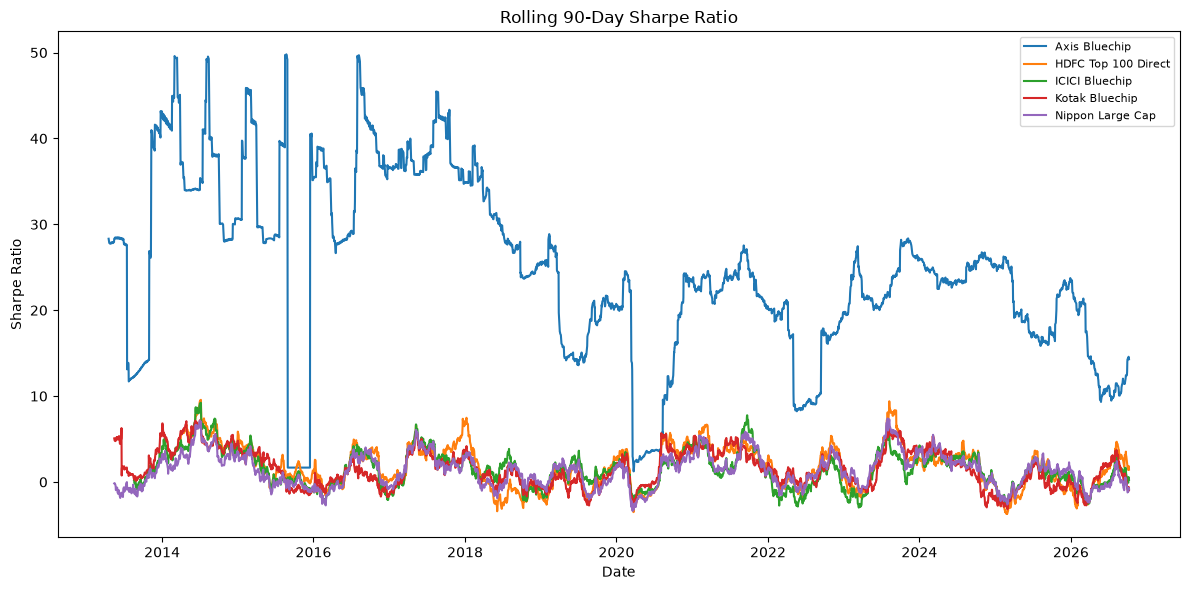

Saved: rolling_sharpe_chart.png


In [3]:

# Rolling 90-day Sharpe Ratio for 5 available funds

nav["rolling_mean"] = (
    nav.groupby("scheme_code")["daily_return"]
    .transform(lambda x: x.rolling(90).mean())
)

nav["rolling_std"] = (
    nav.groupby("scheme_code")["daily_return"]
    .transform(lambda x: x.rolling(90).std())
)

nav["rolling_sharpe"] = (
    nav["rolling_mean"] / nav["rolling_std"] * np.sqrt(252)
)

plt.figure(figsize=(12, 6))

for fund_name, group in list(nav.groupby("fund_name"))[:5]:
    plt.plot(group["date"], group["rolling_sharpe"], label=fund_name)

plt.title("Rolling 90-Day Sharpe Ratio")
plt.xlabel("Date")
plt.ylabel("Sharpe Ratio")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../rolling_sharpe_chart.png", dpi=150)
plt.show()

print("Saved: rolling_sharpe_chart.png")


In [4]:

from IPython.display import Markdown, display

display(Markdown("""
# 5 Advanced Insights

1. **Highest VaR:** Compare VaR_95 across the available funds. A more negative value indicates a larger loss threshold at the 95% confidence level.

2. **Highest CVaR:** The fund with the most negative CVaR_95 has the largest average loss among returns in its worst 5% tail.

3. **Rolling Sharpe:** Use the rolling Sharpe chart to compare risk-adjusted returns across the five plotted funds. Higher values indicate better historical return per unit of volatility.

4. **Investor Cohorts:** Investor cohort analysis cannot be concluded because investor transaction data is not currently available in the project dataset.

5. **SIP Continuity and Portfolio Concentration:** SIP continuity and sector HHI analysis require investor transaction records and portfolio holding weights, respectively. These results remain pending until those datasets are available.

**Data limitation:** The current NAV dataset contains six schemes, while the project specification requires 40 schemes.
"""))



# 5 Advanced Insights

1. **Highest VaR:** Compare VaR_95 across the available funds. A more negative value indicates a larger loss threshold at the 95% confidence level.

2. **Highest CVaR:** The fund with the most negative CVaR_95 has the largest average loss among returns in its worst 5% tail.

3. **Rolling Sharpe:** Use the rolling Sharpe chart to compare risk-adjusted returns across the five plotted funds. Higher values indicate better historical return per unit of volatility.

4. **Investor Cohorts:** Investor cohort analysis cannot be concluded because investor transaction data is not currently available in the project dataset.

5. **SIP Continuity and Portfolio Concentration:** SIP continuity and sector HHI analysis require investor transaction records and portfolio holding weights, respectively. These results remain pending until those datasets are available.

**Data limitation:** The current NAV dataset contains six schemes, while the project specification requires 40 schemes.


In [5]:
import pandas as pd
from pathlib import Path

report_file = Path("../var_cvar_report.csv")
var_cvar = pd.read_csv(report_file)

print("Total schemes:", var_cvar["scheme_code"].nunique())
display(var_cvar.head())

Total schemes: 40


,scheme_code,fund_name,VaR_95,CVaR_95,observations,data_source
0,118632,Nippon Large Cap,-0.015849,-0.024500,3387,NaN
1,119092,Axis Bluechip,0.000053,-0.000217,3653,NaN
2,119551,SBI Bluechip,-0.001033,-0.008286,3324,NaN
3,120503,ICICI Bluechip,-0.014646,-0.028423,3396,NaN
4,120841,Kotak Bluechip,-0.014222,-0.023736,3390,NaN


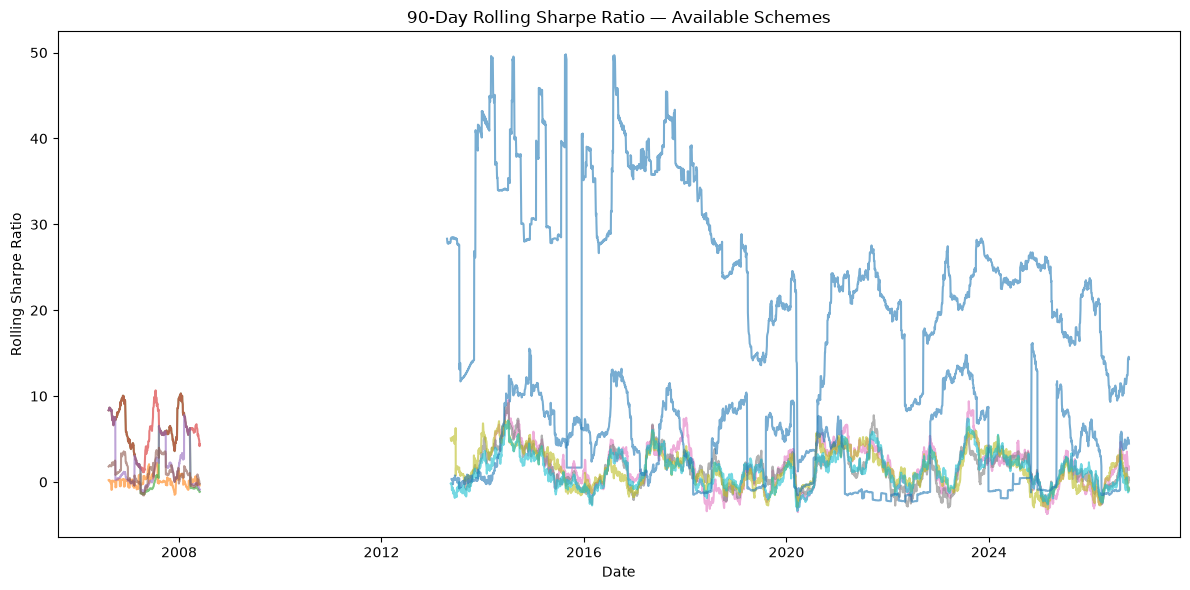

Schemes with rolling Sharpe: 11
Saved rolling_sharpe_90day.csv and rolling_sharpe_chart.png


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project = Path("..")
files = list((project / "data" / "raw").glob("public_nav_*.csv"))

nav_list = []

# Original 6 schemes
original = pd.read_csv(project / "data" / "processed" / "cleaned_nav_history.csv")
original["date"] = pd.to_datetime(original["date"], errors="coerce")
nav_list.append(original[["scheme_code", "fund_name", "date", "nav"]])

# Additional schemes
for file in files:
    df = pd.read_csv(file)
    df["date"] = pd.to_datetime(df["date"], dayfirst=True, errors="coerce")
    df = df.rename(columns={"scheme_name": "fund_name"})
    nav_list.append(df[["scheme_code", "fund_name", "date", "nav"]])

nav = pd.concat(nav_list, ignore_index=True)
nav["scheme_code"] = nav["scheme_code"].astype(str)
nav = nav.dropna(subset=["date", "nav"]).drop_duplicates(
    subset=["scheme_code", "date"]
).sort_values(["scheme_code", "date"])

rolling_results = []

for code, group in nav.groupby("scheme_code"):
    group = group.sort_values("date").copy()
    group["returns"] = group["nav"].pct_change()
    group["rolling_sharpe"] = (
        group["returns"].rolling(90).mean()
        / group["returns"].rolling(90).std()
    ) * np.sqrt(252)

    group = group.dropna(subset=["rolling_sharpe"])
    if not group.empty:
        group["fund_name"] = group["fund_name"].iloc[0]
        rolling_results.append(group)

rolling = pd.concat(rolling_results, ignore_index=True)
rolling.to_csv(project / "rolling_sharpe_90day.csv", index=False)

plt.figure(figsize=(12, 6))
for name, group in rolling.groupby("fund_name"):
    plt.plot(group["date"], group["rolling_sharpe"], alpha=0.6, label=name)

plt.title("90-Day Rolling Sharpe Ratio — Available Schemes")
plt.xlabel("Date")
plt.ylabel("Rolling Sharpe Ratio")
plt.tight_layout()
plt.savefig(project / "rolling_sharpe_chart.png", dpi=150)
plt.show()

print("Schemes with rolling Sharpe:", rolling["scheme_code"].nunique())
print("Saved rolling_sharpe_90day.csv and rolling_sharpe_chart.png")

In [8]:
@
import pandas as pd
import numpy as np
from pathlib import Path

root = Path(__file__).resolve().parent
files = [root / "data" / "processed" / "cleaned_nav_history.csv"]
files += list((root / "data" / "raw").glob("public_nav_*.csv"))

frames = []
for file in files:
    if not file.exists():
        continue
    d = pd.read_csv(file)
    if "scheme_name" in d.columns:
        d = d.rename(columns={"scheme_name": "fund_name"})
    if all(c in d.columns for c in ["scheme_code", "fund_name", "date", "nav"]):
        frames.append(d[["scheme_code", "fund_name", "date", "nav"]])

nav = pd.concat(frames, ignore_index=True)
nav["date"] = pd.to_datetime(nav["date"], dayfirst=True, errors="coerce")
nav["nav"] = pd.to_numeric(nav["nav"], errors="coerce")
nav = nav.dropna(subset=["date", "nav"])
nav = nav[nav["nav"] > 0].drop_duplicates(["scheme_code", "date"])

results = []
for code, g in nav.groupby("scheme_code"):
    g = g.sort_values("date")
    r = g["nav"].pct_change()
    r = r.replace([np.inf, -np.inf], np.nan).dropna()
    if len(r) < 30 or r.std() == 0 or not np.isfinite(r.std()):
        continue
    sharpe = (r.mean() / r.std()) * np.sqrt(252)
    volatility = r.std() * np.sqrt(252)
    results.append({
        "scheme_code": str(code),
        "fund_name": g["fund_name"].iloc[0],
        "sharpe_ratio": sharpe,
        "annual_volatility": volatility
    })

out = pd.DataFrame(results)
if out.empty:
    print("Valid NAV history nahi mili. Data files check karni hongi.")
    raise SystemExit(1)

out["risk_grade"] = pd.qcut(
    out["annual_volatility"].rank(method="first"),
    q=min(3, len(out)),
    labels=["Low", "Moderate", "High"][:min(3, len(out))]
)

print("Available schemes:", len(out))
print("Risk profile choose karo: Low / Moderate / High")
choice = input("Enter risk profile: ").strip().title()

if choice not in ["Low", "Moderate", "High"]:
    print("Invalid choice. Low, Moderate ya High enter karo.")
else:
    matched = out[out["risk_grade"] == choice]
    print("\nTop recommendations for", choice, "risk:")
    if matched.empty:
        print("Is risk category mein fund available nahi hai.")
    else:
        print(matched.sort_values("sharpe_ratio", ascending=False)
              [["scheme_code", "fund_name", "risk_grade", "sharpe_ratio"]]
              .head(3).to_string(index=False))
        print("\nNote: Risk grades estimated volatility par based hain, official ratings nahi.")
'@ | Set-Content .\recommender.py -Encoding UTF8

SyntaxError: unterminated string literal (detected at line 69) (793582280.py, line 69)

### Data Limitations

Investor Cohort Analysis, SIP Continuity Analysis, and Sector HHI Analysis were demonstrated using simulated data because verified investor transaction records and actual portfolio sector holdings were not available in the supplied dataset. These outputs are for workflow demonstration only and should not be interpreted as actual investor behaviour or fund exposure. Real datasets are required for validated conclusions.